In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const

import sys
RE_path = './RE_Solver/' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

import RE as RE

In [ ]:
def getf(v, n0, vT0, tau):
    """
    Corrected Maxwellian with tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT0: initial thermal speed (m/s)
    tau: no units
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT0**3)
    expo = -((v**3/vT0**3) + 3*tau)**(2/3)
    return prefactor * np.exp(expo)

def getfm(v, n0, vT):
    """
    Basic one without tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT: current thermal speed (m/s)
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT**3)
    expo = -((v**2/vT**2))
    return prefactor * np.exp(expo)


def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: decay time (s)
    """
    return Tf + (T0 - Tf) * np.exp(-t / t0)

def getnu0(n, T0):
    """
    T: temp (joules)
    vT: initial time (s)
    returns rate in s^-1
    """
    vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
    lnL = 15 
    return n*const.e**4 * lnL/(4*np.pi * const.epsilon_0**2 * const.m_e**2 * vT0**3)

def getTau(nu0, t, t0):
    """
    t0: initial time (s)
    t: time (s)
    nu0: collision rate (s^-1)
    returns:
    tau (no unit) 
    """
    #return nu0 * max(0.0, t - t0)
    return nu0 * max(0.0, t - 0)

def get_vc(T,E,ne):
    lnA = 15
    Ed = RE.getDreicerField(ne,lnA,T) # V/m
    vc2 = (T * const.e / const.m_e) * (Ed / E)
    return np.sqrt(vc2)

# define the hot-tail function

def getHT(n0,T0,E0,T,t,t0):
    # n0 [per cubic m] = density
    # T0 [eV] = initial temperature
    # T [eV] = temperature at time t
    # E0 [V/m] = initial E-field 
    # t [s] = time
    # t0 [s] = temp. decay time
    
    # thermal velocities
    vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
    vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
    
    # Collision freq.
    nu0 = getnu0(n0, T0)
    
    # get the distribution function
    x = np.linspace(0, 50, int(5e4))      # x = (v / vT0)^2
    v = np.sqrt(x)*vT0
    fm = getfm(v, n0, vT) # cold maxwellian
    tau = getTau(nu0, t, t0)
    f = getf(v, n0, vT0, tau) # hot population
    ftot = fm + f # total distribution
    
    # Electric field
    E = E0 * (T/T0)**(-3/2)
    vc = get_vc(T,E,n0) # m/s
    
    # Now integrate from vc to inf
    idx = np.argwhere(v >= vc)
    idx = idx.flatten()
    return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m
    

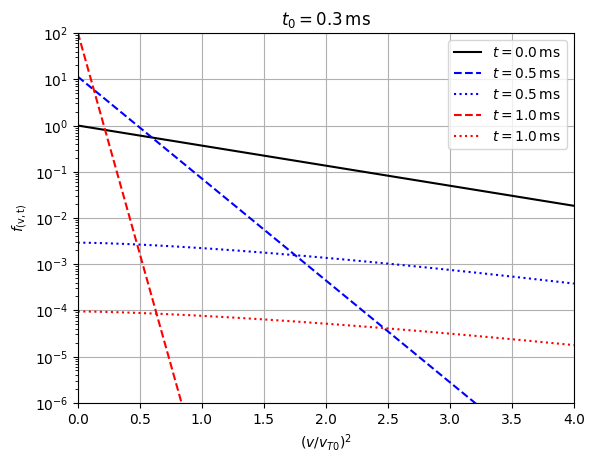

In [3]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3

tau = 0
vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s

x = np.linspace(0, 25, int(1e4))      # x = (v / vT0)^2
v = np.sqrt(x)*vT0
fm = getfm(v, n0, vT0)
norm_fac = max(fm)

plt.plot(x, fm/norm_fac, "k", label=rf"$t = {tau*1e3:.1f}\,\mathrm{{ms}}$")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim((0,4))
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.3\,\mathrm{ms}$")

plt.grid(True)

t = 5e-4
T = temperature(t, T0, Tf, t0)
vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "b--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "b:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

t = 1e-3
T = temperature(t, T0, Tf, t0)
vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "r--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "r:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

plt.legend()


C:\Users\grace\AppData\Local\Temp\ipykernel_31724\2968169305.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  den = np.trapz(4 * np.pi * v**2 * ftot,v)
C:\Users\grace\AppData\Local\Temp\ipykernel_31724\2968169305.py:51: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  nht = np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx])
C:\Users\grace\AppData\Local\Temp\ipykernel_31724\935587859.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


ne = 2.8e+19 per cubic m
integral[ftot] = 2.86e+19 per cubic m
t = 2.000 ms
T = 34.906 eV
E = 8.369 V/m
vc = 15165027.128 m/s
(vc/vT0)**2 = 0.211 m/s
vc = 15165027.128 m/s
nht/n0 = 1.58e-06 
nht/n0 = 1.58e-06 


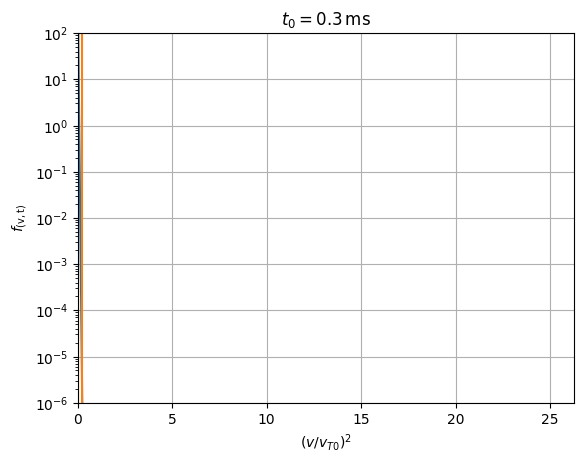

In [4]:
t = 2e-3 # [s]
T = temperature(t, T0, Tf, t0) # eV
vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
fm = getfm(v, n0, vT)

nu0 = getnu0(n0, T0)
vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)

ftot = fm + f # Full distribution function

# Plot
plt.plot((v/vT0)**2, ftot/norm_fac)
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim(xmin=0)
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.3\,\mathrm{ms}$")
plt.grid()

# Integrate the full distribution function
den = np.trapz(4 * np.pi * v**2 * ftot,v)
print('ne = %1.3g per cubic m' %n0)
print('integral[ftot] = %1.3g per cubic m' %den)

# Integrate from vmin = vc
E0 = 0.01 # V/m (this was not givenin the paper; I back-caluclated it as shown in the next cell)
E = E0 * (T/T0)**(-3/2)
vc = get_vc(T,E,n0) # m/s

print('t = %1.3f ms'%(t*1e3))
print('T = %1.3f eV'%T)
print('E = %1.3f V/m'%E)
print('vc = %1.3f m/s'%vc)
print('(vc/vT0)**2 = %1.3f m/s'%(vc/vT0)**2)

# Check vc calculation
ED0 = RE.getDreicerField(n0,15,T0)
t1 = np.sqrt((T0*const.e*ED0)/(const.m_e*E0))
t2 = (T/T0)**0.75 * (n0/n0)**0.5
print('vc = %1.3f m/s'%(t1*t2))

# Plot vc on figure
plt.plot([(vc/vT0)**2]*2,[1e-6,1e2])

# Now integrate from vc to inf
idx = np.argwhere(v > vc)
idx = idx.flatten()
nht = np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx])
print('nht/n0 = %1.3g '%(nht/n0))


# Check function implementation
nht = getHT(n0,T0,E0,T,t,t0)
print('nht/n0 = %1.3g '%(nht/n0))


C:\Users\grace\AppData\Local\Temp\ipykernel_60452\935587859.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


Text(0.5, 0, 't [ms]')

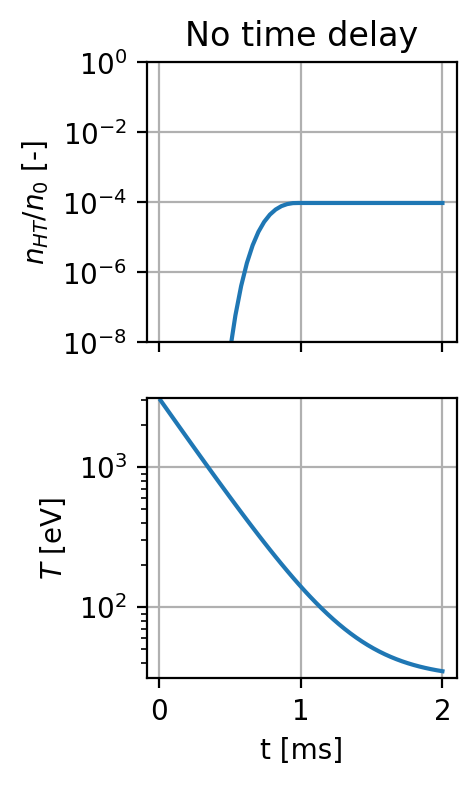

In [5]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]


fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].set_title("No time delay")
axs[0].plot(t*1e3,nht/n0)
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0))
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    
    
    
    


In [21]:
def dHT_dt(n0, T0, Tf, E0, t, t0, dt=1e-6):
    """
    Numerical time derivative of the hot-tail integral using
    T(t) = Tf + (T0 - Tf) exp(-t/t0)

    Parameters
    ----------
    n0 : float
        Density [m^-3]
    T0 : float
        Initial temperature [eV]
    Tf : float
        Final temperature [eV]
    E0 : float
        Initial electric field [V/m]
    t : float
        Time [s]
    t0 : float
        Temperature decay time [s]
    dt : float
        Time step for finite difference [s]
    """

    T_plus  = temperature(t, T0, Tf, t0)
    print('T_plus:', T_plus)
    T_minus = temperature(t, T0, Tf, t0)
    print('T_minus:', T_minus)
    HT_plus = getHT(n0, T0, E0, T_plus,  t + dt, t0)
    print('HT_plus:', HT_plus)
    HT_minus= getHT(n0, T0, E0, T_minus, t - dt, t0)
    print('HT_minus:', HT_minus)
    return (HT_plus - HT_minus) / (2 * dt)


In [7]:
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

dt = 1e-4 * t0


Text(0.5, 0, 't [ms]')

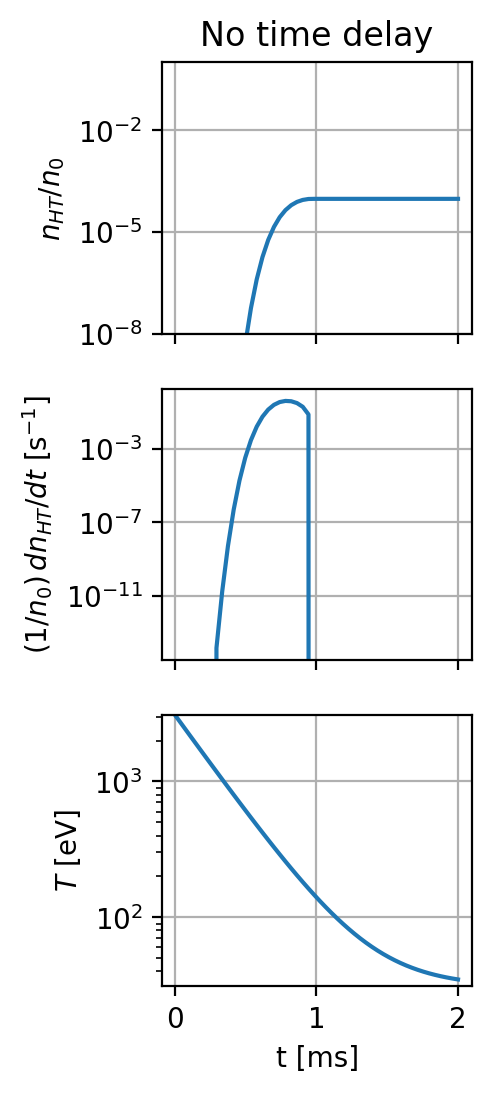

In [6]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = RE.getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]

dt = 1e-3 * t0
dnht_dt = np.zeros_like(t)

for ii in range(1, t.shape[0]-1):
    dnht_dt[ii] = RE.dHT_dt(
        n0=n0,
        T0=T0,
        Tf=Tf,
        E0=E0,
        t=t[ii],
        t0=t0,
        dt=dt
    )

    # Enforce Eq. 19 validity condition: dnht/dt >= 0
    if dnht_dt[ii] < 0:
        dnht_dt[ii] = 0.0


fig, axs = plt.subplots(3, 1, sharex=True, figsize=(2,6), dpi=200)

# --- HT density ---
axs[0].set_title("No time delay")
axs[0].plot(t*1e3, nht/n0)
axs[0].set_ylabel(r'$n_{HT}/n_0$')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8, 1e0])
axs[0].grid()

# --- HT derivative ---
axs[1].plot(t*1e3, dnht_dt/n0)
axs[1].set_ylabel(r'$(1/n_0)\,dn_{HT}/dt$ [s$^{-1}$]')
axs[1].set_yscale('log')
#axs[1].set_ylim([1e-2, 1e6])  # adjust if needed
axs[1].grid()

# --- Temperature ---
axs[2].plot(t*1e3, temperature(t, T0, Tf, t0))
axs[2].set_yscale('log')
axs[2].set_ylabel(r'$T$ [eV]')
axs[2].set_ylim([Tf, T0])
axs[2].grid()
axs[2].set_xlabel('t [ms]')

    
    
    
    


C:\Users\grace\AppData\Local\Temp\ipykernel_31724\935587859.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


T_plus: 2623.556080329555
T_minus: 2623.556080329555
HT_plus: 0.0
HT_minus: 0.0
T_plus: 2295.3101499472086
T_minus: 2295.3101499472086
HT_plus: 0.0
HT_minus: 0.0
T_plus: 2008.623741316413
T_minus: 2008.623741316413
HT_plus: 0.0
HT_minus: 0.0
T_plus: 1758.234964834438
T_minus: 1758.234964834438
HT_plus: 0.0
HT_minus: 0.0
T_plus: 1539.5481436224818
T_minus: 1539.5481436224818
HT_plus: 0.0
HT_minus: 0.0
T_plus: 1348.5494637146671
T_minus: 1348.5494637146671
HT_plus: 0.0
HT_minus: 0.0
T_plus: 1181.7333038548552
T_minus: 1181.7333038548552
HT_plus: 1.8815256542359782
HT_minus: 1.8816319269409245
T_plus: 1036.037892746227
T_minus: 1036.037892746227
HT_plus: 2871.6456953445822
HT_minus: 2871.8229776183252
T_plus: 908.7891127961851
T_minus: 908.7891127961851
HT_plus: 1094545.5474769864
HT_minus: 1094619.1727410126
T_plus: 797.6514189212462
T_minus: 797.6514189212462
HT_plus: 133575055.96884324
HT_minus: 133584805.62763168
T_plus: 700.5849715675745
T_minus: 700.5849715675745
HT_plus: 6385667789

Text(0.5, 0, 't [ms]')

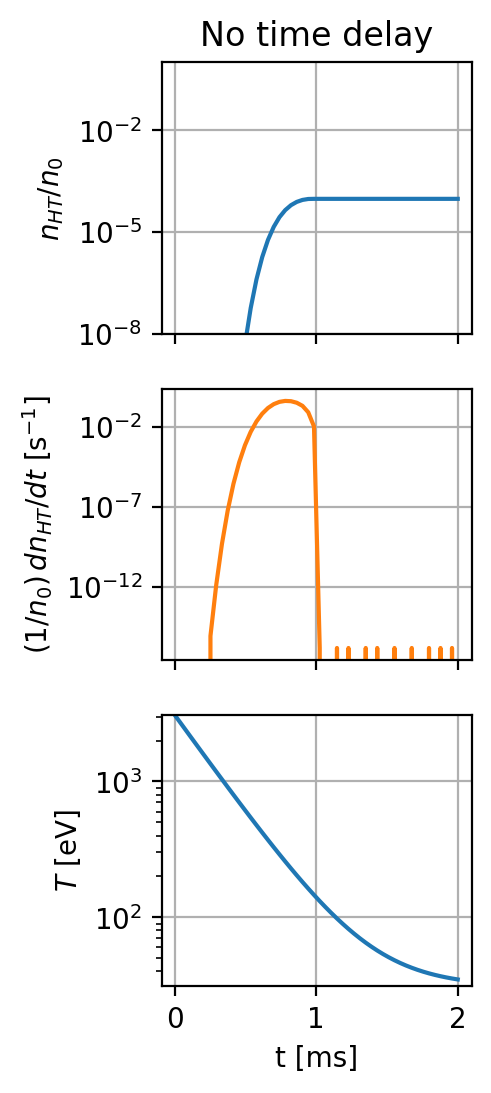

In [31]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

ht_plus = np.zeros_like(t)
ht_minus = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    ht_plus[ii] = getHT(n0,T0,E0,temperature(t[ii]+1e-6, T0, Tf, t0),t[ii]+1e-6,t0)
    ht_minus[ii] = getHT(n0,T0,E0,temperature(t[ii]-1e-6, T0, Tf, t0),t[ii]-1e-6,t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]

dt = 1e-3 * t0
dnht_dt = np.zeros_like(t)

for ii in range(1, t.shape[0]-1):
    dnht_dt[ii] = dHT_dt(
        n0=n0,
        T0=T0,
        Tf=Tf,
        E0=E0,
        t=t[ii],
        t0=t0,
        dt=1e-8
    )

    # Enforce Eq. 19 validity condition: dnht/dt >= 0
    if dnht_dt[ii] < 0:
        dnht_dt[ii] = 0.0

grad = np.gradient(nht, t)


fig, axs = plt.subplots(3, 1, sharex=True, figsize=(2,6), dpi=200)

# --- HT density ---
axs[0].set_title("No time delay")
axs[0].plot(t*1e3, nht/n0)
axs[0].set_ylabel(r'$n_{HT}/n_0$')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8, 1e0])
axs[0].grid()

# --- HT derivative ---
axs[1].plot(t*1e3, dnht_dt/n0)
axs[1].plot(t*1e3, grad/n0)
axs[1].set_ylabel(r'$(1/n_0)\,dn_{HT}/dt$ [s$^{-1}$]')
axs[1].set_yscale('log')
#axs[1].set_ylim([1e-2, 1e6])  # adjust if needed
axs[1].grid()

# --- Temperature ---
axs[2].plot(t*1e3, temperature(t, T0, Tf, t0))
axs[2].set_yscale('log')
axs[2].set_ylabel(r'$T$ [eV]')
axs[2].set_ylim([Tf, T0])
axs[2].grid()
axs[2].set_xlabel('t [ms]')

    
    
    
    


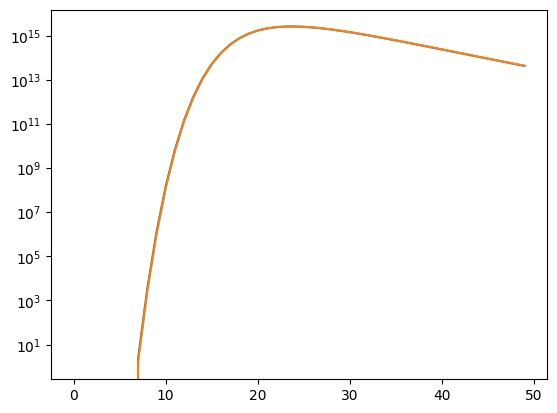

In [32]:
plt.plot(ht_plus)
plt.plot(ht_minus)
plt.yscale("log")

In [13]:
temperature(1e-3, 5e3, 10, 1e-4)

np.float64(10.226545649514799)

In [14]:
temperature(1e-3 + 1e-7, 5e3, 10, 1e-4)

np.float64(10.226319217100361)

In [7]:
solver = RE.solver0D()
solver.display() 

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


Hot tail on: 4094594.222686824
Hot tail off 4094594.222686824


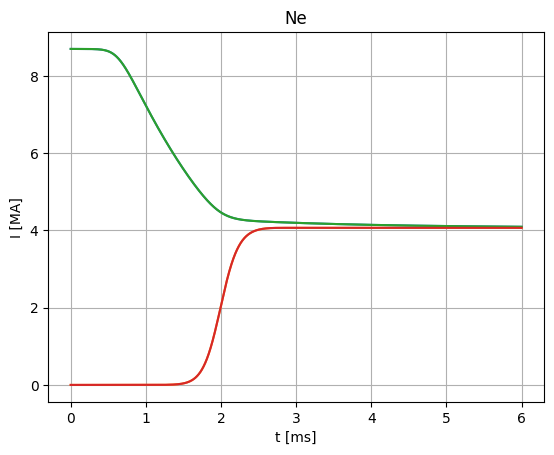

In [8]:
solver = RE.solver0D()


solver.k = 1.7
solver.Ir0 = 1
solver.iDreicer = 1
solver.iHotTail = 1
solver.tmax = 6e-3

# Set impurity properties
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e21

# Solve
t, Ip, Ir, Wk = solver.solve()
print("Hot tail on:", Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title('Ne')

solver = RE.solver0D()


solver.k = 1.7
solver.Ir0 = 1
solver.iDreicer = 1
solver.iHotTail = 0
solver.tmax = 6e-3

# Set impurity properties
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e21

# Solve
t, Ip, Ir, Wk = solver.solve()
print("Hot tail off", Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')


In [17]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = RE.getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]

dt = 1e-3 * t0
dnht_dt = np.zeros_like(t)

for ii in range(1, t.shape[0]-1):
    T = temperature(t[ii], T0, Tf, t0)
    dnht_dt[ii] = dHT_dt(
        n0=n0,
        T0=T0,
        E0=E0,
        T = T,
        t=t[ii],
        t0=t0,
        dt=dt
    )

    # Enforce Eq. 19 validity condition: dnht/dt >= 0
    if dnht_dt[ii] < 0:
        dnht_dt[ii] = 0.0


fig, axs = plt.subplots(3, 1, sharex=True, figsize=(2,6), dpi=200)

# --- HT density ---
axs[0].set_title("No time delay")
axs[0].plot(t*1e3, nht/n0)
axs[0].set_ylabel(r'$n_{HT}/n_0$')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8, 1e0])
axs[0].grid()

# --- HT derivative ---
axs[1].plot(t*1e3, dnht_dt/n0)
axs[1].set_ylabel(r'$(1/n_0)\,dn_{HT}/dt$ [s$^{-1}$]')
axs[1].set_yscale('log')
#axs[1].set_ylim([1e-2, 1e6])  # adjust if needed
axs[1].grid()

# --- Temperature ---
axs[2].plot(t*1e3, temperature(t, T0, Tf, t0))
axs[2].set_yscale('log')
axs[2].set_ylabel(r'$T$ [eV]')
axs[2].set_ylim([Tf, T0])
axs[2].grid()
axs[2].set_xlabel('t [ms]')

    
    
    
    


TypeError: dHT_dt() got an unexpected keyword argument 'T'

C:\Users\grace\AppData\Local\Temp\ipykernel_29212\935587859.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m
C:\Users\grace\AppData\Local\Temp\ipykernel_29212\935587859.py:63: RuntimeWarning: divide by zero encountered in scalar divide
  vc2 = (T * const.e / const.m_e) * (Ed / E)


T_plus: 0.01
T_minus: 0.01
HT_plus: 0.0
HT_minus: 0.0
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140419764806277e+18
HT_minus: 1.1327295871610486e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420416879141e+18
HT_minus: 1.1327296535388433e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420634236764e+18
HT_minus: 1.1327296756647748e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420742915576e+18
HT_minus: 1.1327296867277408e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420808122861e+18
HT_minus: 1.13272969336552e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420851594386e+18
HT_minus: 1.1327296977907063e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420882645476e+18
HT_minus: 1.1327297009515538e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420905933791e+18
HT_minus: 1.1327297033221894e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420924046926e+18
HT_minus: 1.1327297051660169e+18
T_plus: 0.01
T_minus: 0.01
HT_plus: 1.1140420938537436e+18
HT_minus: 1.132729706641079e+18
T_plus: 0.01
T_minus: 0.01
HT

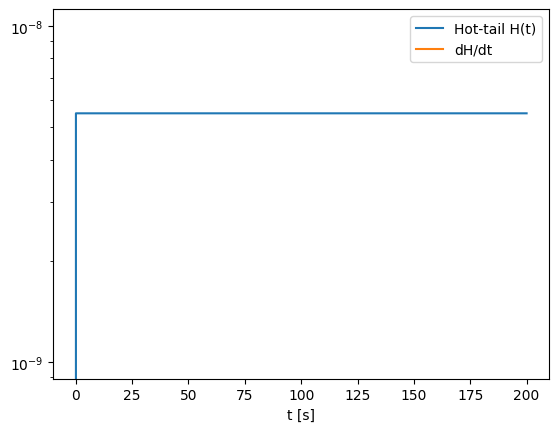

In [37]:
xmax = max(200, 5 * (vc / vT0)**2)
x = np.linspace(0, xmax, int(2e3))


HTs = []
dHTs = []

for t in x:
    Tt = temperature(t, T0, Tf, t0)

    HTs.append(getHT(n0, T0, E0, Tt, t, t0)/n0)
    dHTs.append(dHT_dt(
        n0, T0, E0,
        t,
        t0, dt
    ))
print(dHTs)
plt.figure()
plt.plot(x, HTs, label="Hot-tail H(t)")
plt.plot(x, dHTs, label="dH/dt")
plt.xlabel("t [s]")
plt.yscale('log')
plt.legend()
plt.show()


In [ ]:
n0 = 1e20
T0 = 100
Tf = 10
E0 = 5
t0 = 1e-3

t = 3e-4

T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

dt = 1e-5 * t0

print('HT:', getHT(n0, T0, E0, T, t, t0))
print('dHT_dt:', dHT_dt(n0, T0, Tf, E0, t, t0, dt))


HT: 2.1516690108525937e+18
T_plus: 1606.6613816184251
T_minus: 1606.692895161192
HT_plus: 0.0
HT_minus: 0.0
dHT_dt: 0.0


C:\Users\grace\AppData\Local\Temp\ipykernel_29212\935587859.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


In [27]:
def debug_vc(T, label):
    E = E0 * (T/T0)**(-3/2)
    vc = get_vc(T, E, n0)
    print(f"{label}: vc = {vc:.3e}, vmax = {np.sqrt(50)*np.sqrt(2*T0*const.e/const.m_e):.3e}")

debug_vc(temperature(t, T0, Tf, t0), "t")
debug_vc(temperature(t+dt, T0, Tf, t0), "t+dt")
debug_vc(temperature(t-dt, T0, Tf, t0), "t-dt")


t: vc = 2.680e+08, vmax = 2.335e+08
t+dt: vc = 2.678e+08, vmax = 2.335e+08
t-dt: vc = 2.682e+08, vmax = 2.335e+08


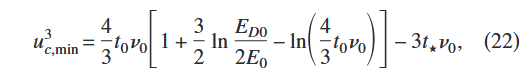

In [57]:
def get_uc_min(t0, nu0, ED0overE0, t_star):
    """
    Calculates u_{c,min} from Equation 22.
    
    Parameters:
    t0     : characteristic time t_0
    nu0    : collision frequency nu_0
    ED0    : Dreicer field E_D0
    E0     : Electric field E_0
    t_star : time parameter t_*
    """
    # Pre-calculate the repeated term (4/3 * t0 * nu0)
    base_term = (4/3) * t0 * nu0
    
    # Calculate the argument for the inner natural log
    # (E_D0 / 2E_0) - ln(4/3 * t0 * nu0)
    ln_arg = (ED0overE0/2) - np.log(base_term)
    
    # Calculate the full term in the square brackets
    # [1 + 3/2 * ln(...)]
    bracket_term = 1 + 1.5 * np.log(ln_arg)
    
    # Calculate u_{c,min}^3
    uc_min_cubed = (base_term * bracket_term) - (3 * t_star * nu0)
    
    # Return the cube root to get u_{c,min}
    # np.cbrt handles negative values correctly if they arise
    return np.cbrt(uc_min_cubed)

def fn(x):
    T0 = 3.1e3
    n0 = 2.8e19
    t_star = 0.3e-3
    t0 = t_star
    nu0 = getnu0(n0, T0)
    uc_min = get_uc_min(t0, nu0, x, t_star)
    return 1e-3 - 2/np.sqrt(np.pi) * uc_min * np.exp(-uc_min**2)

from scipy.optimize import fsolve

# E0 is not given so backcaluclate based on Fig. 5 (Eqn. 23)
ED0 = RE.getDreicerField(n0,15,T0)
print('Ed0 = %1.3g V/m'%ED0)
res = fsolve(fn,10)
E0 = ED0 / res
print('E0 = %1.3g V/m'%E0)

# Check
T0 = 3.1e3
n0 = 2.8e19
t_star = 0.3e-3
t0 = t_star
nu0 = getnu0(n0, T0)
uc_min = get_uc_min(t0, nu0, ED0/E0, t0)
nht = 2/np.sqrt(np.pi) * uc_min * np.exp(-uc_min**2)
print('nht/n0 = %1.3g'%nht)

Ed0 = 3.53 V/m
E0 = 0.013 V/m
nht/n0 = 0.001
